# Personalized Artist Recommendation — Collaborative Filtering (User-based CF)

**How to run:** In Colab, choose `Runtime > Run all` and upload the preprocessed ZIP. Results are saved to `/content/cf_outputs`. (For local runs, the `DATA_DIR` folder is read.)

**Evaluation rules (the same as the CBF notebook):** Settings are selected only by **Dataset A validation NDCG@10**. A-test and B validation/test are used only for the evaluation and diagnosis of the fixed settings. On B, A's user similarities are not imported; the similarities among B users are **recomputed** (only the algorithm structure is carried over).

### Overall Processing Flow
`Load preprocessed data → data validation → data exploration → user × artist matrix → cosine user similarity → k-neighbor score → Top-10 recommendation → A-validation setting selection (k, weighting) → A-test evaluation → B external evaluation (recomputation + repeated samples) → popularity, per-user, confidence interval, and case analyses → automatic checks and saving`

**Comparison baseline:** Popularity recommendation: from the train history, it recommends 10 artists in descending order of the number of distinct listeners per artist, excluding artists already heard.

**Compatibility with the CBF notebook:** The recommendation format (`user_id, artist_id, score, rank`) and the `evaluate()` function are used **identically** to the CBF notebook, so that the three methods (CF, CBF, Popularity) can be compared with the same metrics.

In [1]:
import os, io, sys, json, zipfile, pathlib, hashlib, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import sparse
from sklearn.preprocessing import normalize
from IPython.display import display

SEED = 42
np.random.seed(SEED)
TOPK = 10
try:
    import google.colab  # Check whether running in Colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
OUT = pathlib.Path('/content/cf_outputs') if IN_COLAB else pathlib.Path.cwd() / 'cf_outputs'
OUT.mkdir(parents=True, exist_ok=True)
DATA_DIR = pathlib.Path('data')   # For local runs: the folder where the preprocessed ZIP was extracted
print('Colab:', IN_COLAB, '| 결과 저장 위치:', OUT)

Colab: True | 결과 저장 위치: /content/cf_outputs


## 1. Load the Preprocessed Data

Only the files needed for collaborative filtering are read from the preprocessed ZIP.

| File | Purpose |
|---|---|
| `Lastfm.2k-a/{train,validation,test}.csv` | A user similarity computation (train), setting selection (validation), final evaluation (test) |
| `Lastfm.360k-b/{train,validation,test}.csv` | **Recompute** B user similarity (train), recheck A's settings (validation), external evaluation (test) |
| `Lastfm.2k-a/artists.csv` | Recommendation IDs → artist names; `content_eligible` for a fair comparison with CBF |
| `Lastfm.360k-b/artists.csv` | Show names of B recommendations (optional) |

The `content_external_candidates/` folder is for content-based evaluation and is not used. Files are searched by **path pattern** so that they can be found even if the folder structure differs slightly. The CSVs have a UTF-8 BOM, so they are read with `utf-8-sig`.

In [2]:
def list_sources():
    """Return (list of relative paths, function to open a file) from an uploaded ZIP (Colab) or a local folder"""
    if IN_COLAB:
        from google.colab import files
        uploaded = files.upload()
        zip_names = [k for k in uploaded if k.lower().endswith('.zip')]
        assert len(zip_names) == 1, '전처리 ZIP 파일 하나만 업로드하세요.'
        zb = uploaded[zip_names[0]]
        print('원본 ZIP SHA256:', hashlib.sha256(zb).hexdigest())
        z = zipfile.ZipFile(io.BytesIO(zb))
        return [n for n in z.namelist() if not n.endswith('/')], z.open
    assert DATA_DIR.exists(), f'{DATA_DIR} 폴더가 없습니다.'
    names = [str(p.relative_to(DATA_DIR)).replace(os.sep, '/') for p in DATA_DIR.rglob('*') if p.is_file()]
    return names, lambda n: open(DATA_DIR / n, 'rb')

A_KEYS, B_KEYS = ('2k', 'data_a'), ('360k', 'data_b')   # Candidate strings so the folders can be found even if their names differ
def pick(names, musts, endswith, exclude=('content_external', '__MACOSX'), required=True):
    """Find exactly one file whose path contains one of musts and ends with the given suffix"""
    hits = [n for n in names if any(m in n.lower() for m in musts) and n.endswith(endswith) and not any(e in n for e in exclude)]
    if not required and not hits:
        return None
    assert len(hits) == 1, f'{musts} *{endswith}: 후보 {hits}'
    return hits[0]

names, opener = list_sources()
read = lambda n: pd.read_csv(opener(n), encoding='utf-8-sig', low_memory=False)
PATHS = {f'{d}_{s}': pick(names, key, f'/{s}.csv') for d, key in [('A', A_KEYS), ('B', B_KEYS)]
         for s in ('train', 'validation', 'test')}
PATHS['A_artists'] = pick(names, A_KEYS, '/artists.csv')
PATHS['B_artists'] = pick(names, B_KEYS, '/artists.csv', required=False)
for k, v in PATHS.items(): print(f'{k:13s} <- {v}')

a = {s: read(PATHS[f'A_{s}']) for s in ('train', 'validation', 'test')}
b = {s: read(PATHS[f'B_{s}']) for s in ('train', 'validation', 'test')}
a_art = read(PATHS['A_artists'])
b_art = read(PATHS['B_artists']) if PATHS['B_artists'] else pd.DataFrame(columns=['artist_id', 'name'])
for label, parts in [('A', a), ('B', b)]:
    for s, d in parts.items(): print(label, s, d.shape)

Saving 전처리데이터.zip to 전처리데이터.zip
원본 ZIP SHA256: 9ef1b2df065009cc6e3be0060835b06ac171f42cefe267f9d6178d3f0ffff8ae
A_train       <- Lastfm.2k-a/train.csv
A_validation  <- Lastfm.2k-a/validation.csv
A_test        <- Lastfm.2k-a/test.csv
B_train       <- Lastfm.360k-b/train.csv
B_validation  <- Lastfm.360k-b/validation.csv
B_test        <- Lastfm.360k-b/test.csv
A_artists     <- Lastfm.2k-a/artists.csv
B_artists     <- Lastfm.360k-b/artists.csv
A train (55721, 6)
A validation (18540, 6)
A test (18540, 6)
B train (301797, 6)
B validation (93948, 6)
B test (93948, 6)


## 2. Schema, ID, Split, and Leakage Validation

The data is only inspected, not modified. The same criteria as in the CBF notebook are used.
- Required columns exist, no missing values, `plays > 0`, `log1p_plays = log(1+plays)`
- No duplicate `(user_id, artist_id)` within a split
- **No identical `(user_id, artist_id)` across train, validation, and test** (leakage prevention)
- The user sets of the three splits are identical (every evaluation user has a training history)

`artist_index` is not a common numbering between A and B, so it is **not used for joins**; everything is handled with `user_id` and `artist_id`.

In [3]:
REQ = ['user_index', 'artist_index', 'user_id', 'artist_id', 'plays', 'log1p_plays']
def audit_splits(parts, label):
    keys = []
    for split, df in parts.items():
        missing = set(REQ) - set(df.columns)
        assert not missing, f'{label} {split} 컬럼 누락: {missing}'
        assert df[REQ].notna().all().all(), f'{label} {split}: 결측'
        assert (df.plays > 0).all()
        assert np.allclose(np.log1p(df.plays.to_numpy()), df.log1p_plays.to_numpy(), atol=1e-8)
        assert not df.duplicated(['user_id', 'artist_id']).any(), f'{label} {split}: 중복 interaction'
        keys.append(pd.MultiIndex.from_frame(df[['user_id', 'artist_id']]))
    for i in range(3):
        for j in range(i + 1, 3):
            assert len(keys[i].intersection(keys[j])) == 0, f'{label}: {list(parts)[i]}/{list(parts)[j]} 누수'
    for split, df in parts.items():
        assert set(df.user_id) == set(parts['train'].user_id), f'{label}: 사용자 집합 불일치'
    print(label, '검증 통과 — 분할 간 중복 없음, 사용자 집합 일치')
audit_splits(a, 'A'); audit_splits(b, 'B')
assert set(a['train'].artist_id) <= set(a_art.artist_id), 'A artist_id가 카탈로그에 없음'

A 검증 통과 — 분할 간 중복 없음, 사용자 집합 일치
B 검증 통과 — 분할 간 중복 없음, 사용자 집합 일치


## 3. Data Exploration

Collaborative filtering is strongly affected by **how filled the user × artist matrix is (sparsity)** and by **popularity concentration (long tail)**.
- **Sparsity** = 1 − (number of observed listens ÷ (number of users × number of artists))
- **Cold item:** An artist in the validation/test ground truth that never appears in train cannot be recommended by CF in principle (since nobody has a listening record for it). This ratio is checked in advance.

dataset,A (Last.fm 2K),B (Last.fm 360K sample)
users,1877.000000,9997.000000
train_artists,12904.000000,42655.000000
train_rows,55721.000000,301797.000000
sparsity,0.997699,0.999292
median_artists_per_user(train),30.000000,30.000000
median_listeners_per_artist(train),1.000000,1.000000
validation_rows,18540.000000,93948.000000
validation_cold_item_rate,0.143204,0.073126
test_rows,18540.000000,93948.000000
test_cold_item_rate,0.144283,0.073509


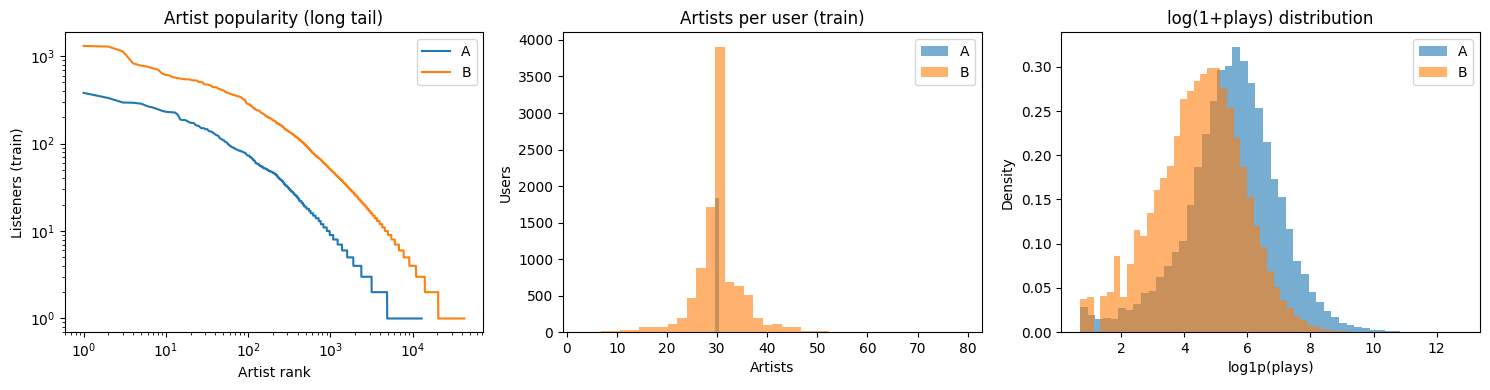

In [4]:
def explore(parts, name):
    tr = parts['train']
    n_u, n_i = tr.user_id.nunique(), tr.artist_id.nunique()
    seen_art = set(tr.artist_id)
    row = {'dataset': name, 'users': n_u, 'train_artists': n_i, 'train_rows': len(tr),
           'sparsity': 1 - len(tr) / (n_u * n_i),
           'median_artists_per_user(train)': tr.groupby('user_id').size().median(),
           'median_listeners_per_artist(train)': tr.groupby('artist_id').size().median()}
    for s in ('validation', 'test'):
        row[f'{s}_rows'] = len(parts[s])
        row[f'{s}_cold_item_rate'] = (~parts[s].artist_id.isin(seen_art)).mean()
    return row
eda = pd.DataFrame([explore(a, 'A (Last.fm 2K)'), explore(b, 'B (Last.fm 360K sample)')]).set_index('dataset').T
display(eda); eda.to_csv(OUT / 'data_exploration.csv')

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for d, name in [(a, 'A'), (b, 'B')]:
    lc = d['train'].groupby('artist_id').user_id.nunique().sort_values(ascending=False).to_numpy()
    axs[0].loglog(np.arange(1, len(lc) + 1), lc, label=name)
    axs[1].hist(d['train'].groupby('user_id').size(), bins=40, alpha=.6, label=name)
    axs[2].hist(d['train'].log1p_plays, bins=50, alpha=.6, density=True, label=name)
axs[0].set(title='Artist popularity (long tail)', xlabel='Artist rank', ylabel='Listeners (train)')
axs[1].set(title='Artists per user (train)', xlabel='Artists', ylabel='Users')
axs[2].set(title='log(1+plays) distribution', xlabel='log1p(plays)', ylabel='Density')
for ax in axs: ax.legend()
plt.tight_layout(); plt.savefig(OUT / 'data_exploration.png', dpi=160); plt.show()

## 4. User-based CF Model and the Popularity Baseline

**(1) User × artist matrix $R$:** rows = users, columns = artists, values = preference signals. Play counts are implicit feedback, so two weightings are compared.
- `log`: $r_{ui} = \log(1+\text{plays})$: heavier weight for artists listened to more, with extreme values softened
- `binary`: 1 if listened: play counts are ignored

**(2) User similarity (cosine):** If each user vector is L2-normalized, the dot product is exactly the cosine similarity.
$$\text{sim}(u,v)=\frac{\mathbf r_u\cdot\mathbf r_v}{\lVert\mathbf r_u\rVert\,\lVert\mathbf r_v\rVert}$$

**(3) k-nearest-neighbor score:** The listening records of the $k$ users $N_k(u)$ most similar to user $u$ (excluding the user) are summed with similarity weights.
$$\text{score}(u,i)=\sum_{v\in N_k(u)} \text{sim}(u,v)\, r_{vi}$$

**(4) Top-10:** Artists already heard are excluded and the 10 artists with the highest scores are recommended. Artists that no neighbor listened to (score 0) are not recommended.

**Recommendation candidates:** CF can recommend only artists that appear at least once in the training history. This candidate set is the denominator of Catalog Coverage.

**Memory handling:** B has about 10,000 users, so building the user × user similarity matrix at once is large (about 800 MB); the users are therefore processed in `batch` units. The result equals computing it all at once.

In [5]:
def build_matrix(history, artist_ids, value='log'):
    """[Description] User x artist sparse matrix R. value='log' uses log1p(plays), 'binary' uses 1"""
    users = sorted(history.user_id.unique().tolist())
    uidx = {u: i for i, u in enumerate(users)}
    aidx = {x: i for i, x in enumerate(artist_ids)}
    h = history[history.artist_id.isin(aidx)]
    if value == 'log':
        vals = h.log1p_plays.to_numpy(dtype=float)
    elif value == 'binary':
        vals = np.ones(len(h))
    else:
        raise ValueError(value)
    R = sparse.csr_matrix((vals, (h.user_id.map(uidx).to_numpy(), h.artist_id.map(aidx).to_numpy())),
                          shape=(len(users), len(artist_ids)))
    return users, R

def neighbor_similarity(Rn, start, end, k):
    """[Description] Build the cosine-similarity rows for users start..end (batch x all users) and keep only the top k"""
    S = (Rn[start:end] @ Rn.T).toarray()
    np.fill_diagonal(S[:, start:end], 0.0)              # Exclude the user itself from the neighbors
    if k < S.shape[1]:
        drop = np.argpartition(-S, k, axis=1)[:, k:]    # Positions outside the top k
        np.put_along_axis(S, drop, 0.0, axis=1)         # -> set to 0 to drop them from the neighbors
    return S

def recommend_ucf(history, k=50, value='log', topk=TOPK, allowed=None, batch=512):
    """[Description] User-based CF Top-k recommendation.
    history: observed listening history / k: number of neighbors / value: 'log'|'binary' / allowed: set of artists allowed for recommendation (None = all)
    Returns: (recommendation DataFrame[user_id, artist_id, score, rank], list of candidates)"""
    cand = sorted(history.artist_id.unique().tolist())
    users, R = build_matrix(history, cand, value)
    Rn = normalize(R, norm='l2', axis=1)
    seen = (R > 0).tocsr()
    block = None if allowed is None else ~np.isin(np.array(cand, dtype=object), list(allowed))
    out_u, out_a, out_s, out_r = [], [], [], []
    cand_arr = np.array(cand, dtype=object)
    for s in range(0, len(users), batch):
        e = min(s + batch, len(users))
        S = neighbor_similarity(Rn, s, e, k)
        scores = (sparse.csr_matrix(S) @ R).toarray()   # Σ sim(u,v)·r(v,i)
        scores[seen[s:e].toarray()] = -np.inf             # Exclude artists already heard
        if block is not None:
            scores[:, block] = -np.inf                    # Restrict candidates (supplementary experiment)
        top = np.argpartition(-scores, topk, axis=1)[:, :topk]
        for j in range(e - s):
            idx = top[j][np.argsort(-scores[j, top[j]], kind='stable')]
            idx = idx[scores[j, idx] > 0]                 # Drop artists that no neighbor listened to
            out_u += [users[s + j]] * len(idx); out_a += cand_arr[idx].tolist()
            out_s += scores[j, idx].tolist(); out_r += list(range(1, len(idx) + 1))
    recs = pd.DataFrame({'user_id': out_u, 'artist_id': out_a, 'score': out_s, 'rank': out_r})
    if allowed is not None:
        cand = [x for x in cand if x in allowed]
    return recs, cand

def recommend_pop(history, topk=TOPK, allowed=None):
    """[Description] Popularity baseline: descending number of distinct listeners per artist (ties by artist_id), excluding artists already heard"""
    pop = history.groupby('artist_id').user_id.nunique().rename('n').reset_index()
    if allowed is not None:
        pop = pop[pop.artist_id.isin(allowed)]
    pop['key'] = pop.artist_id.astype(str)
    pop = pop.sort_values(['n', 'key'], ascending=[False, True])
    order, counts = pop.artist_id.tolist(), pop.n.tolist()
    seen = history.groupby('user_id').artist_id.agg(set).to_dict()
    rec = []
    for u in sorted(seen):
        r = 0
        for x, c in zip(order, counts):
            if x in seen[u]: continue
            r += 1; rec.append((u, x, float(c), r))
            if r == topk: break
    return pd.DataFrame(rec, columns=['user_id', 'artist_id', 'score', 'rank']), order

# Small behavior check: user 0 has the same taste as user 1, so 'C', which user 1 heard, must be recommended
_h = pd.DataFrame({'user_id': [0, 0, 1, 1, 1, 2], 'artist_id': ['A', 'B', 'A', 'B', 'C', 'D'], 'plays': 1})
_h['log1p_plays'] = np.log1p(_h.plays)
_r, _ = recommend_ucf(_h, k=1, topk=2)
assert _r[_r.user_id == 0].artist_id.tolist() == ['C'], _r
print('CF 단위 테스트 통과')

CF 단위 테스트 통과


## 5. Metric Definitions (the same functions as in the CBF notebook)

| Metric | Computation and meaning |
|---|---|
| Precision@10 | Number of hits ÷ 10 |
| Recall@10 | Number of hits ÷ number of all hidden listened artists |
| NDCG@10 | Ranking metric that is higher when hits are placed higher (DCG/IDCG) |
| Catalog Coverage | Number of distinct artists recommended at least once ÷ number of recommendation candidates |

The official metrics are based on **all held-out ground truth**, and the `conditional_*` metrics that count only ground truth inside the candidate set are supplementary. For users whose list could not be filled with 10 items, the Precision denominator is still 10.

In [6]:
# [Source] evaluate() of the teammate’s CBF notebook used without modification, to compare the three methods under the same standard
def evaluate(recs, truth, users, candidate_ids, k=10):
    users = list(users); truth_by = truth.groupby('user_id').artist_id.agg(set).to_dict()
    pred_by = recs.sort_values('rank').groupby('user_id').artist_id.agg(list).to_dict() if len(recs) else {}
    cand = set(candidate_ids); discount = 1 / np.log2(np.arange(2, k + 2))
    records = []
    for u in users:
        gt = truth_by.get(u, set()); pred = pred_by.get(u, [])
        assert len(gt) > 0, f'{u}: 정답 없는 사용자'
        hit = np.array([int(x in gt) for x in pred[:k]], dtype=float)
        dcg = float((hit * discount[:len(hit)]).sum())
        reachable = gt & cand
        records.append({'user_id': u, 'precision10': float(hit.sum() / k),
           'recall10': float(hit.sum() / len(gt)),
           'ndcg10': float(dcg / discount[:min(k, len(gt))].sum()),
           'conditional_recall10': float(hit.sum() / len(reachable)) if reachable else np.nan,
           'conditional_ndcg10': float(dcg / discount[:min(k, len(reachable))].sum()) if reachable else np.nan,
           'gt_count': len(gt), 'reachable_gt': len(reachable), 'hits': int(hit.sum()), 'recommendations': len(pred)})
    per = pd.DataFrame(records)
    summary = {c: float(per[c].mean()) for c in ['precision10', 'recall10', 'ndcg10', 'conditional_recall10', 'conditional_ndcg10']}
    summary.update({'catalog_coverage': float(recs.artist_id.nunique() / len(cand)),
       'reachable_gt_fraction': float(per.reachable_gt.sum() / per.gt_count.sum()),
       'users': len(users), 'users_with_reachable_gt': int((per.reachable_gt > 0).sum()),
       'recommended_users': int((per.recommendations > 0).sum()), 'catalog_size': len(cand)})
    return summary, per

_t = pd.DataFrame({'user_id': ['u'], 'artist_id': [101]})
_r = pd.DataFrame({'user_id': ['u'], 'artist_id': [101], 'rank': [1], 'score': [1.]})
_s, _ = evaluate(_r, _t, ['u'], [101, 102], 10)
assert np.isclose(_s['precision10'], .1) and np.isclose(_s['recall10'], 1.) and np.isclose(_s['ndcg10'], 1.)
print('평가 지표 단위 테스트 통과')

평가 지표 단위 테스트 통과


## 6. Dataset A Validation: Selecting the Neighborhood Size k and Weighting

Search range fixed in advance: **k ∈ {5, 10, 20, 30, 50, 75, 100, 150, 200, 300}** × **weighting ∈ {log, binary}** (20 combinations).
- Similarities and neighbors are computed from **A-train only**, and evaluated with A-validation as the ground truth.
- **Final selection criterion: maximum A-validation NDCG@10** (ties: Recall@10 → Precision@10 → smaller k). A-test and B do not take part in this selection.
- The popularity baseline is also evaluated under the same conditions.

그리드 탐색 16.3초


,value,k,precision10,recall10,ndcg10,catalog_coverage
0,log,30,0.141236,0.143214,0.162347,0.055719
1,log,50,0.138306,0.140383,0.161949,0.042777
2,binary,50,0.137666,0.140194,0.159878,0.044560
3,log,20,0.138839,0.140550,0.159725,0.068971
4,log,75,0.136335,0.138414,0.159387,0.036655
5,binary,30,0.138253,0.140793,0.159200,0.057269
6,binary,75,0.135269,0.137659,0.158008,0.036655
7,log,100,0.135376,0.137465,0.157962,0.033246
8,binary,100,0.135216,0.137720,0.156642,0.033555
9,binary,20,0.136921,0.139399,0.155534,0.070986


Popularity (A validation) NDCG@10 = 0.0709, Recall@10 = 0.0635
확정 설정: k = 30 | weight = log


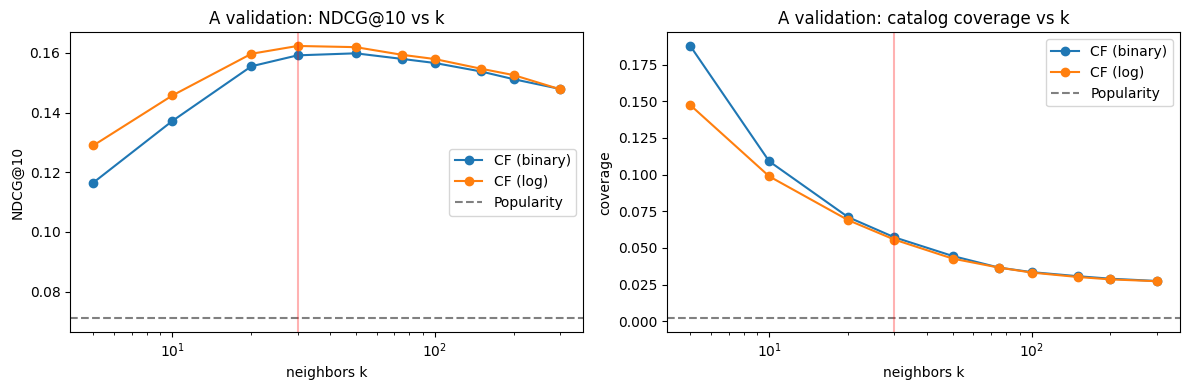

In [7]:
K_GRID = [5, 10, 20, 30, 50, 75, 100, 150, 200, 300]
A_TRAIN_USERS = sorted(a['train'].user_id.unique())
rows = []
t0 = time.time()
for value in ['log', 'binary']:
    for k in K_GRID:
        rec, cand = recommend_ucf(a['train'], k=k, value=value)
        summ, _ = evaluate(rec, a['validation'], A_TRAIN_USERS, cand)
        rows.append({'value': value, 'k': k, **summ})
pop_val, pop_order = recommend_pop(a['train'])
pop_val_sum, _ = evaluate(pop_val, a['validation'], A_TRAIN_USERS, pop_order)
print(f'그리드 탐색 {time.time() - t0:.1f}초')
val_df = (pd.DataFrame(rows).sort_values(['ndcg10', 'recall10', 'precision10', 'k'], ascending=[False, False, False, True])
          .reset_index(drop=True))
display(val_df[['value', 'k', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage']].head(10))
print('Popularity (A validation) NDCG@10 = %.4f, Recall@10 = %.4f' % (pop_val_sum['ndcg10'], pop_val_sum['recall10']))
val_df.to_csv(OUT / 'A_validation_model_selection.csv', index=False)
BEST_K, BEST_VALUE = int(val_df.iloc[0].k), str(val_df.iloc[0].value)
print('확정 설정: k =', BEST_K, '| weight =', BEST_VALUE)
(OUT / 'selected_config.json').write_text(json.dumps({'method': 'user-based CF (cosine)', 'k': BEST_K, 'weight': BEST_VALUE,
    'selection': 'Dataset A validation NDCG@10', 'k_grid': K_GRID, 'seed': SEED}, indent=2))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for value, g in pd.DataFrame(rows).groupby('value'):
    g = g.sort_values('k')
    axs[0].plot(g.k, g.ndcg10, marker='o', label=f'CF ({value})')
    axs[1].plot(g.k, g.catalog_coverage, marker='o', label=f'CF ({value})')
axs[0].axhline(pop_val_sum['ndcg10'], color='gray', ls='--', label='Popularity')
axs[1].axhline(pop_val_sum['catalog_coverage'], color='gray', ls='--', label='Popularity')
axs[0].set(xscale='log', title='A validation: NDCG@10 vs k', xlabel='neighbors k', ylabel='NDCG@10')
axs[1].set(xscale='log', title='A validation: catalog coverage vs k', xlabel='neighbors k', ylabel='coverage')
for ax in axs: ax.axvline(BEST_K, color='red', alpha=.3); ax.legend()
plt.tight_layout(); plt.savefig(OUT / 'A_validation_k_curve.png', dpi=160); plt.show()

## 7. Final Internal Evaluation: Dataset A Test

**Important:** After the settings are fixed, user similarities are recomputed with `A train + A validation` as the observed history, and **only A-test is used as the ground truth** (the same rule as in the CBF notebook). Test listening records enter neither the similarity nor the popularity computation.

In [8]:
a_hist = pd.concat([a['train'], a['validation']], ignore_index=True)
A_USERS = sorted(a_hist.user_id.unique())
a_cf, A_CF_CAND = recommend_ucf(a_hist, k=BEST_K, value=BEST_VALUE)
a_pop, A_POP_CAND = recommend_pop(a_hist)
A_CF_SUM, A_CF_PER = evaluate(a_cf, a['test'], A_USERS, A_CF_CAND)
A_POP_SUM, A_POP_PER = evaluate(a_pop, a['test'], A_USERS, A_POP_CAND)

### 7-1. (Supplementary) Comparison on the Same Recommendation Candidates as CBF

CBF recommends only artists with 2 or more tags (`content_eligible=1`), so its candidate set differs from CF's. To reduce the distortion caused by the candidate difference, we also report results with **the recommendation candidates of CF and popularity restricted to artists that overlap with the CBF candidates**. The official results are the unrestricted results above.

In [9]:
CBF_ELIGIBLE = set(a_art.loc[a_art.content_eligible.eq(1), 'artist_id'])
a_cf_r, A_CF_CAND_R = recommend_ucf(a_hist, k=BEST_K, value=BEST_VALUE, allowed=CBF_ELIGIBLE)
a_pop_r, A_POP_CAND_R = recommend_pop(a_hist, allowed=CBF_ELIGIBLE)
A_CF_SUM_R, _ = evaluate(a_cf_r, a['test'], A_USERS, A_CF_CAND_R)
A_POP_SUM_R, _ = evaluate(a_pop_r, a['test'], A_USERS, A_POP_CAND_R)

A_SUMMARY = pd.DataFrame([{'model': f'User-CF (k={BEST_K}, {BEST_VALUE})', 'candidates': 'all observed', **A_CF_SUM},
                          {'model': 'Popularity', 'candidates': 'all observed', **A_POP_SUM},
                          {'model': f'User-CF (k={BEST_K}, {BEST_VALUE})', 'candidates': 'CBF-eligible only', **A_CF_SUM_R},
                          {'model': 'Popularity', 'candidates': 'CBF-eligible only', **A_POP_SUM_R}])
cols = ['model', 'candidates', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'catalog_size', 'reachable_gt_fraction', 'recommended_users']
display(A_SUMMARY[cols]); A_SUMMARY.to_csv(OUT / 'A_test_summary.csv', index=False)
print('제한 없는 CF 추천 중 CBF 후보(태그 있는 아티스트) 비율: %.2f%%' % (100 * a_cf.artist_id.isin(CBF_ELIGIBLE).mean()))

,model,candidates,precision10,recall10,ndcg10,catalog_coverage,catalog_size,reachable_gt_fraction,recommended_users
0,"User-CF (k=30, log)",all observed,0.166276,0.169190,0.203930,0.047062,15384,0.872708,1877
1,Popularity,all observed,0.066862,0.068533,0.078313,0.001690,15384,0.872708,1877
2,"User-CF (k=30, log)",CBF-eligible only,0.166276,0.169190,0.203930,0.076345,9444,0.851564,1877
3,Popularity,CBF-eligible only,0.066862,0.068533,0.078313,0.002753,9444,0.851564,1877


제한 없는 CF 추천 중 CBF 후보(태그 있는 아티스트) 비율: 99.95%


## 8. External Evaluation: Dataset B (User Similarity Recomputed)

B users do not exist in A, so A's similarities cannot be carried over. Instead, **the algorithm structure fixed on A** (cosine user-based CF, weighting, k) is applied to B unchanged, and the similarities among B users are recomputed.

1. **Recheck on B validation (diagnostic):** The k grid is evaluated again with B-train only, only to check that the k chosen on A is also appropriate on B. **k is not changed by this result.**
2. **Final evaluation on B-test:** Similarities are computed with the `B train + B validation` history and evaluated on B-test.

In [10]:
B_TRAIN_USERS = sorted(b['train'].user_id.unique())
t0 = time.time(); bv_rows = []
for k in K_GRID:
    rec, cand = recommend_ucf(b['train'], k=k, value=BEST_VALUE)
    summ, _ = evaluate(rec, b['validation'], B_TRAIN_USERS, cand)
    bv_rows.append({'k': k, **summ})
bv_df = pd.DataFrame(bv_rows)
b_pop_val, b_pop_val_order = recommend_pop(b['train'])
BV_POP_SUM, _ = evaluate(b_pop_val, b['validation'], B_TRAIN_USERS, b_pop_val_order)
print(f'B validation 진단 {time.time() - t0:.1f}초')
display(bv_df[['k', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage']])
best_b = bv_df.sort_values('ndcg10', ascending=False).iloc[0]
a_k_row = bv_df.loc[bv_df.k.eq(BEST_K)].iloc[0]
print(f'B validation 최고 k = {int(best_b.k)} (NDCG@10 {best_b.ndcg10:.4f}) | A에서 고른 k = {BEST_K} (NDCG@10 {a_k_row.ndcg10:.4f}, '
      f'최고 대비 {a_k_row.ndcg10 / best_b.ndcg10:.1%}) | Popularity {BV_POP_SUM["ndcg10"]:.4f}')
bv_df.to_csv(OUT / 'B_validation_k_diagnostic.csv', index=False)

b_hist = pd.concat([b['train'], b['validation']], ignore_index=True)
B_USERS = sorted(b_hist.user_id.unique())
b_cf, B_CF_CAND = recommend_ucf(b_hist, k=BEST_K, value=BEST_VALUE)
b_pop, B_POP_CAND = recommend_pop(b_hist)
B_CF_SUM, B_CF_PER = evaluate(b_cf, b['test'], B_USERS, B_CF_CAND)
B_POP_SUM, B_POP_PER = evaluate(b_pop, b['test'], B_USERS, B_POP_CAND)

B validation 진단 122.5초


,k,precision10,recall10,ndcg10,catalog_coverage
0,5,0.067960,0.072488,0.082700,0.199367
1,10,0.080494,0.085859,0.097219,0.132482
2,20,0.090557,0.096652,0.109311,0.091314
3,30,0.094788,0.100978,0.114102,0.073848
4,50,0.096289,0.102595,0.115629,0.056898
5,75,0.095749,0.102021,0.115244,0.047216
6,100,0.095019,0.101263,0.114341,0.041800
7,150,0.092788,0.098886,0.111180,0.036151
8,200,0.090857,0.096800,0.109006,0.032775
9,300,0.087436,0.093119,0.104944,0.029258


B validation 최고 k = 50 (NDCG@10 0.1156) | A에서 고른 k = 30 (NDCG@10 0.1141, 최고 대비 98.7%) | Popularity 0.0377


### 8-1. Stability over Repeated Samples (different sampling seeds)

As promised in the proposal, **5,000 of the B users are drawn at random 5 times with different seeds**, and each time the matrix and similarities are rebuilt from only those users and evaluated. The mean ± standard deviation of the results shows the variation by sample. (The settings are exactly those fixed on A, and test is not used for tuning.)

In [11]:
REPEAT_SEEDS, SAMPLE_USERS = [0, 1, 2, 3, 4], 5000
rep = []
for sd in REPEAT_SEEDS:
    us = set(np.random.default_rng(sd).choice(np.array(B_USERS, dtype=object), SAMPLE_USERS, replace=False))
    h = b_hist[b_hist.user_id.isin(us)]; t = b['test'][b['test'].user_id.isin(us)]
    uu = sorted(us)
    r1, c1 = recommend_ucf(h, k=BEST_K, value=BEST_VALUE); s1, _ = evaluate(r1, t, uu, c1)
    r2, c2 = recommend_pop(h); s2, _ = evaluate(r2, t, uu, c2)
    for m, s in [('User-CF', s1), ('Popularity', s2)]:
        rep.append({'seed': sd, 'model': m, **{x: s[x] for x in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']}})
rep_df = pd.DataFrame(rep); rep_df.to_csv(OUT / 'B_repeated_sampling.csv', index=False)
rep_sum = rep_df.groupby('model')[['precision10', 'recall10', 'ndcg10', 'catalog_coverage']].agg(['mean', 'std'])
display(rep_sum.round(4))

precision10         recall10          ndcg10          \
                  mean     std     mean     std    mean     std   
model                                                             
Popularity      0.0316  0.0004   0.0336  0.0004  0.0385  0.0006   
User-CF         0.1075  0.0007   0.1149  0.0009  0.1337  0.0012   

           catalog_coverage          
                       mean     std  
model                                
Popularity           0.0006  0.0000  
User-CF              0.0624  0.0013

In [12]:
B_SUMMARY = pd.DataFrame([{'model': f'User-CF (k={BEST_K}, {BEST_VALUE})', **B_CF_SUM}, {'model': 'Popularity', **B_POP_SUM}])
display(B_SUMMARY[['model', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'catalog_size', 'reachable_gt_fraction', 'users']])
B_SUMMARY.to_csv(OUT / 'B_test_summary.csv', index=False)
for name, df in [('A_test_CF_user_metrics', A_CF_PER), ('A_test_POP_user_metrics', A_POP_PER),
                 ('B_test_CF_user_metrics', B_CF_PER), ('B_test_POP_user_metrics', B_POP_PER),
                 ('A_test_CF_recommendations', a_cf), ('B_test_CF_recommendations', b_cf)]:
    df.to_csv(OUT / (name + '.csv'), index=False)

,model,precision10,recall10,ndcg10,catalog_coverage,catalog_size,reachable_gt_fraction,users
0,"User-CF (k=30, log)",0.116485,0.124935,0.146210,0.064494,48981,0.937572,9997
1,Popularity,0.032170,0.034236,0.039385,0.000470,48981,0.937572,9997


## 9. Confidence Intervals and the CF − Popularity Difference (Bootstrap)

The mean's 95% confidence interval is obtained by **2,000 resamples** at the user level. The score difference between CF and popularity for the same users is also estimated with a **paired bootstrap**. If the confidence interval of the difference does not contain 0, the difference between the two methods is hard to attribute to chance in this evaluation sample.

,dataset,metric,model,mean,ci_low,ci_high
0,A_test,precision10,User-CF,0.1663,0.1597,0.1730
1,A_test,precision10,Popularity,0.0669,0.0621,0.0717
2,A_test,precision10,CF - Popularity (paired),0.0994,0.0939,0.1047
3,A_test,recall10,User-CF,0.1692,0.1625,0.1760
4,A_test,recall10,Popularity,0.0685,0.0636,0.0732
5,A_test,recall10,CF - Popularity (paired),0.1007,0.0951,0.1060
6,A_test,ndcg10,User-CF,0.2039,0.1958,0.2121
7,A_test,ndcg10,Popularity,0.0783,0.0724,0.0841
8,A_test,ndcg10,CF - Popularity (paired),0.1256,0.1188,0.1325
9,B_test,precision10,User-CF,0.1165,0.1143,0.1187


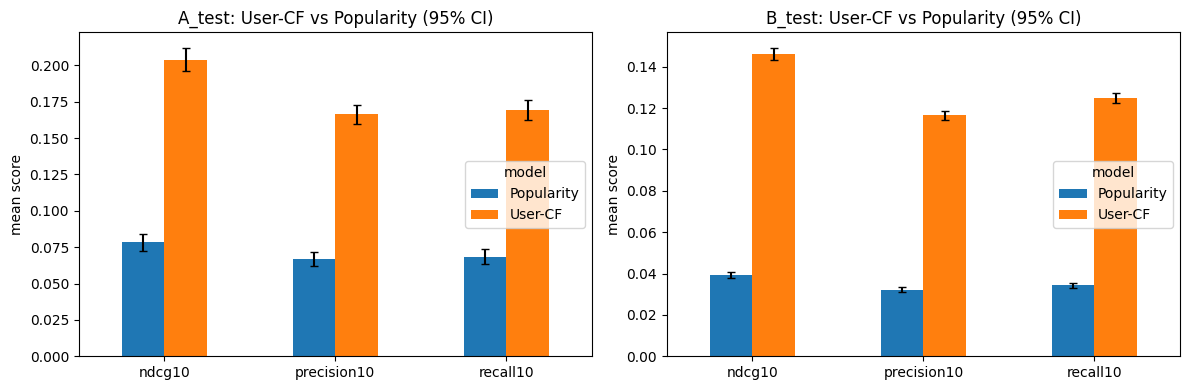

In [13]:
def bootstrap_ci(x, n_boot=2000, seed=SEED):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), size=(n_boot, len(x)))].mean(axis=1)
    return tuple(np.quantile(means, [.025, .975]))
ci = []
for ds, cf_per, pop_per in [('A_test', A_CF_PER, A_POP_PER), ('B_test', B_CF_PER, B_POP_PER)]:
    m = cf_per.merge(pop_per, on='user_id', suffixes=('_cf', '_pop'), validate='one_to_one')
    for metric in ['precision10', 'recall10', 'ndcg10']:
        for label, x in [('User-CF', m[f'{metric}_cf']), ('Popularity', m[f'{metric}_pop']),
                         ('CF - Popularity (paired)', m[f'{metric}_cf'] - m[f'{metric}_pop'])]:
            lo, hi = bootstrap_ci(x)
            ci.append({'dataset': ds, 'metric': metric, 'model': label, 'mean': x.mean(), 'ci_low': lo, 'ci_high': hi})
ci_df = pd.DataFrame(ci); display(ci_df.round(4)); ci_df.to_csv(OUT / 'bootstrap_95ci.csv', index=False)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, ds in zip(axs, ['A_test', 'B_test']):
    d = ci_df[(ci_df.dataset == ds) & (ci_df.model != 'CF - Popularity (paired)')]
    piv = d.pivot(index='metric', columns='model', values='mean')
    err = piv - d.pivot(index='metric', columns='model', values='ci_low')
    piv.plot(kind='bar', ax=ax, yerr=err, capsize=3, rot=0)
    ax.set(title=f'{ds}: User-CF vs Popularity (95% CI)', ylabel='mean score', xlabel='')
plt.tight_layout(); plt.savefig(OUT / 'CF_vs_POP_performance.png', dpi=160); plt.show()

## 10. Popularity Bias and Novelty

In collaborative filtering, artists that many people listened to appear often in neighbors' records, so there is a **tendency to lean toward popular artists**. The popularity of the recommended artists is compared between CF and the popularity baseline (the same definition as in the CBF notebook).
- `listeners`: number of distinct users who listened to the artist in the observed history (train+validation); test is not used
- `novelty = -log2((listeners+1)/(number of users+1))`: larger means a less well-known artist (an observation-based proxy)

,set,mean_listeners,median_listeners,mean_novelty,distinct_artists
0,A User-CF,188.866,175.0,3.690,724
1,A Popularity,355.837,348.0,2.417,26
2,B User-CF,496.927,426.0,4.991,3159
3,B Popularity,1104.178,1008.0,3.232,23


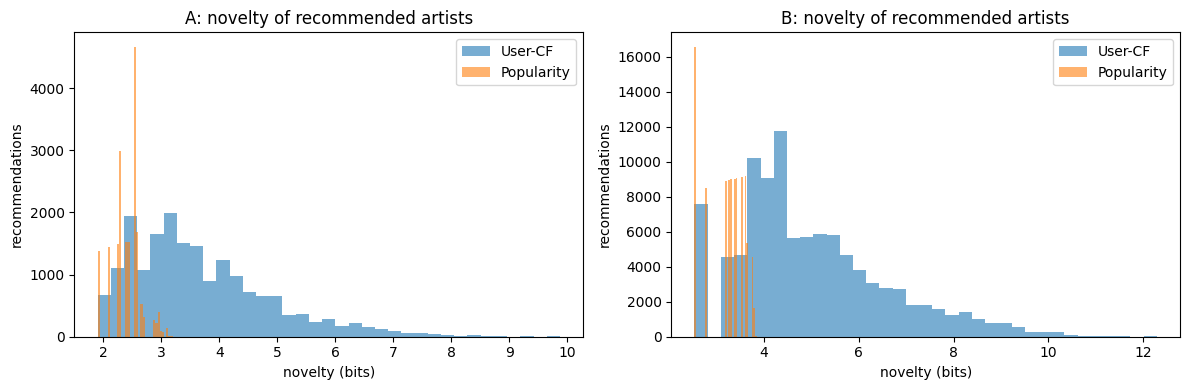

In [14]:
def popularity_analysis(history, recs, name):
    listeners = history.groupby('artist_id').user_id.nunique()
    N = history.user_id.nunique()
    out = recs.copy()
    out['listeners'] = out.artist_id.map(listeners).fillna(0).astype(int)
    out['novelty_bits'] = -np.log2((out.listeners + 1) / (N + 1))
    return out, {'set': name, 'mean_listeners': out.listeners.mean(), 'median_listeners': out.listeners.median(),
                 'mean_novelty': out.novelty_bits.mean(), 'distinct_artists': out.artist_id.nunique()}
pops = []; nov = {}
for ds, hist, recs_cf, recs_pop in [('A', a_hist, a_cf, a_pop), ('B', b_hist, b_cf, b_pop)]:
    for m, r in [('User-CF', recs_cf), ('Popularity', recs_pop)]:
        o, s = popularity_analysis(hist, r, f'{ds} {m}'); pops.append(s); nov[(ds, m)] = o
pop_df = pd.DataFrame(pops); display(pop_df.round(3)); pop_df.to_csv(OUT / 'popularity_novelty_summary.csv', index=False)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, ds in zip(axs, ['A', 'B']):
    for m in ['User-CF', 'Popularity']:
        ax.hist(nov[(ds, m)].novelty_bits, bins=35, alpha=.6, label=m)
    ax.set(title=f'{ds}: novelty of recommended artists', xlabel='novelty (bits)', ylabel='recommendations'); ax.legend()
plt.tight_layout(); plt.savefig(OUT / 'novelty_distribution.png', dpi=160); plt.show()

## 11. Per-User Performance: Differences by History Length

The number of observed listened artists is split into the groups `1~5 / 6~15 / 16~30 / 31+`, and the mean NDCG@10 of CF and popularity is compared. With a short history it is hard to find similar neighbors, so CF may be at a disadvantage. Groups with small samples are not over-interpreted.

In [15]:
def history_groups(cf_per, pop_per, history, name):
    cnt = history.groupby('user_id').artist_id.nunique().rename('observed_artists')
    m = cf_per[['user_id', 'ndcg10', 'recall10']].merge(pop_per[['user_id', 'ndcg10']], on='user_id', suffixes=('_cf', '_pop'))
    m = m.merge(cnt, left_on='user_id', right_index=True, how='left', validate='one_to_one')
    m['history_group'] = pd.cut(m.observed_artists, bins=[0, 5, 15, 30, np.inf], labels=['1-5', '6-15', '16-30', '31+'])
    t = m.groupby('history_group', observed=False).agg(users=('user_id', 'size'), cf_ndcg10=('ndcg10_cf', 'mean'),
                                                        pop_ndcg10=('ndcg10_pop', 'mean')).reset_index()
    t.insert(0, 'dataset', name); return t
hg = pd.concat([history_groups(A_CF_PER, A_POP_PER, a_hist, 'A_test'), history_groups(B_CF_PER, B_POP_PER, b_hist, 'B_test')])
display(hg.round(4)); hg.to_csv(OUT / 'history_group_analysis.csv', index=False)

,dataset,history_group,users,cf_ndcg10,pop_ndcg10
0,A_test,1-5,1,0.0000,0.0000
1,A_test,6-15,16,0.2349,0.1184
2,A_test,16-30,16,0.1928,0.0474
3,A_test,31+,1844,0.2039,0.0783
0,B_test,1-5,3,0.0000,0.0000
1,B_test,6-15,55,0.1276,0.0055
2,B_test,16-30,540,0.1133,0.0210
3,B_test,31+,9399,0.1483,0.0407


## 12. Recommendation Evidence and Success and Failure Cases

The evidence for a CF recommendation is **"because neighbors with taste similar to mine listened to it."** The score $\sum_v \text{sim}(u,v)\,r_{vi}$ of each recommended artist is split into per-neighbor contributions, and the neighbors that contribute most and the number of artists each neighbor listened to together with me are shown. `heldout_hit=True` means a hidden actual listen was hit, and `False` does not mean "dislikes." The cases are for explanation and are not used to adjust the model.

In [16]:
A_NAME = a_art.set_index('artist_id')['name'].to_dict()
B_NAME = b_art.set_index('artist_id')['name'].to_dict() if len(b_art) else {}

def explain_user(user, history, recs, truth, k, value, names, n_recs=5):
    cand = sorted(history.artist_id.unique().tolist())
    users, R = build_matrix(history, cand, value)
    ui = users.index(user); Rn = normalize(R, axis=1)
    S = neighbor_similarity(Rn, ui, ui + 1, k)[0]
    nb = np.nonzero(S)[0]
    aidx = {x: i for i, x in enumerate(cand)}
    mine = set(R[ui].indices)
    gt = set(truth.loc[truth.user_id.eq(user), 'artist_id'])
    rows = []
    for r in recs[recs.user_id.eq(user)].sort_values('rank').head(n_recs).itertuples():
        col = R[:, aidx[r.artist_id]].toarray().ravel()
        contrib = S[nb] * col[nb]
        order = np.argsort(-contrib)[:3]
        why = '; '.join(f'user {users[nb[j]]} (sim {S[nb[j]]:.2f}, shared {len(mine & set(R[nb[j]].indices))})'
                        for j in order if contrib[j] > 0)
        rows.append({'user_id': user, 'rank': r.rank, 'artist': names.get(r.artist_id, r.artist_id), 'score': round(r.score, 3),
                     'heldout_hit': r.artist_id in gt, 'neighbors_listened': int((contrib > 0).sum()), 'top_neighbors': why})
    return pd.DataFrame(rows)

def examples(per, history, recs, truth, names, label):
    good = per[per.hits.gt(0)].sort_values(['ndcg10', 'recall10'], ascending=False).head(1).user_id.tolist()
    bad = per[per.hits.eq(0) & per.recommendations.gt(0)].sort_values('gt_count', ascending=False).head(1).user_id.tolist()
    frames = []
    for typ, ids in [('success', good), ('failure', bad)]:
        for u in ids:
            e = explain_user(u, history, recs, truth, BEST_K, BEST_VALUE, names); e.insert(0, 'case', typ); frames.append(e)
    out = pd.concat(frames, ignore_index=True); out.to_csv(OUT / f'{label}_explained_examples.csv', index=False)
    return out
pd.set_option('display.max_colwidth', 120)
display(examples(A_CF_PER, a_hist, a_cf, a['test'], A_NAME, 'A_test'))
display(examples(B_CF_PER, b_hist, b_cf, b['test'], B_NAME, 'B_test'))

,case,user_id,rank,artist,score,heldout_hit,neighbors_listened,top_neighbors
0,success,797,1,Lady Gaga,51.825,True,24,"user 703 (sim 0.40, shared 6); user 1742 (sim 0.33, shared 7); user 1023 (sim 0.35, shared 5)"
1,success,797,2,Rihanna,49.165,False,24,"user 399 (sim 0.34, shared 6); user 703 (sim 0.40, shared 6); user 1521 (sim 0.33, shared 6)"
2,success,797,3,Miley Cyrus,39.001,False,20,"user 1851 (sim 0.39, shared 6); user 1145 (sim 0.40, shared 8); user 1072 (sim 0.33, shared 5)"
3,success,797,4,Taylor Swift,36.102,True,16,"user 1145 (sim 0.40, shared 8); user 425 (sim 0.37, shared 4); user 1851 (sim 0.39, shared 6)"
4,success,797,5,Beyoncé,33.138,False,20,"user 1071 (sim 0.33, shared 6); user 1742 (sim 0.33, shared 7); user 1072 (sim 0.33, shared 5)"
5,failure,2100,1,Iron Maiden,4.387,False,10,"user 1324 (sim 0.13, shared 5); user 208 (sim 0.14, shared 5); user 1536 (sim 0.05, shared 2)"
6,failure,2100,2,Mayhem,4.270,False,5,"user 586 (sim 0.42, shared 12); user 208 (sim 0.14, shared 5); user 548 (sim 0.14, shared 6)"
7,failure,2100,3,Megadeth,4.145,False,9,"user 491 (sim 0.13, shared 5); user 548 (sim 0.14, shared 6); user 1986 (sim 0.05, shared 2)"
8,failure,2100,4,Black Sabbath,3.905,False,8,"user 586 (sim 0.42, shared 12); user 491 (sim 0.13, shared 5); user 208 (sim 0.14, shared 5)"
9,failure,2100,5,Judas Priest,3.859,False,8,"user 491 (sim 0.13, shared 5); user 548 (sim 0.14, shared 6); user 208 (sim 0.14, shared 5)"


,case,user_id,rank,artist,score,heldout_hit,neighbors_listened,top_neighbors
0,success,4d88f1045ee15daa8adb14b3e6d66a885a3071a7,1,beyonce,7.890,True,12,"user 5223d3037548452dad710ccbe8bc6719de16cdf3 (sim 0.18, shared 3); user 94ec6da04666436bdb05fe0ebd107fd2b87b685d (s..."
1,success,4d88f1045ee15daa8adb14b3e6d66a885a3071a7,2,mariah carey,7.889,False,10,"user f825b717e0e0b9bdfaa31486b52f256b1a803907 (sim 0.30, shared 3); user 94ec6da04666436bdb05fe0ebd107fd2b87b685d (s..."
2,success,4d88f1045ee15daa8adb14b3e6d66a885a3071a7,3,1christina aguilera,7.306,False,10,"user f825b717e0e0b9bdfaa31486b52f256b1a803907 (sim 0.30, shared 3); user a76a7c8ee23a4b124bab6aaee30153bbd6bac527 (s..."
3,success,4d88f1045ee15daa8adb14b3e6d66a885a3071a7,4,lily allen,5.568,False,7,"user 5223d3037548452dad710ccbe8bc6719de16cdf3 (sim 0.18, shared 3); user 705fcba6bf98ae4bfc272cf8a4ea81025d78b3b2 (s..."
4,success,4d88f1045ee15daa8adb14b3e6d66a885a3071a7,5,madonna,5.503,False,7,"user 6279fc82e62cc0b1c445739f0b51a0cff3653fd9 (sim 0.20, shared 3); user caa360223322d4079c37a49cecd33588be27d0ec (s..."
5,failure,16beced39e44bd7f9dfd170be1014cd7df68b73d,1,pink floyd,6.390,False,11,"user 3c4a69288365012701f97173cb82e4f407b5116a (sim 0.16, shared 10); user e5cbeff19737523dda044c1cddeed7e73eaed1f6 (..."
6,failure,16beced39e44bd7f9dfd170be1014cd7df68b73d,2,david bowie,5.760,False,10,"user cc360d0aab6f6bd514e061c7354c8c80c51dd084 (sim 0.13, shared 7); user 2aa75ff35f1f1b37a822115acedad5c58fcfc3db (s..."
7,failure,16beced39e44bd7f9dfd170be1014cd7df68b73d,3,muse,5.288,False,9,"user 3c4a69288365012701f97173cb82e4f407b5116a (sim 0.16, shared 10); user 4815f88a51229e92410c43dcff951214657b8404 (..."
8,failure,16beced39e44bd7f9dfd170be1014cd7df68b73d,4,portishead,5.103,False,8,"user 2aa75ff35f1f1b37a822115acedad5c58fcfc3db (sim 0.12, shared 7); user cc360d0aab6f6bd514e061c7354c8c80c51dd084 (s..."
9,failure,16beced39e44bd7f9dfd170be1014cd7df68b73d,5,bjork,4.954,False,8,"user 2aa75ff35f1f1b37a822115acedad5c58fcfc3db (sim 0.12, shared 7); user 6fd4938f2dd509b19610495e49a4302dde4c7c36 (s..."


## 13. Final Automatic Checks and Saving Results

Whether the recommendation results obey the rules is checked automatically: only artists inside the candidate set are recommended, already-heard artists are excluded, there are no duplicate ranks per user, at most 10 artists, no overlap between the observed history and the test ground truth, and metrics lie in 0 to 1.

In [17]:
def final_checks(history, truth, recs, candidate_ids, summary, name):
    seen = history.groupby('user_id').artist_id.agg(set).to_dict()
    assert set(recs.artist_id) <= set(candidate_ids), f'{name}: 후보 밖 추천'
    assert not any(x in seen[u] for u, x in zip(recs.user_id, recs.artist_id)), f'{name}: 이미 들은 아티스트 추천'
    assert not recs.duplicated(['user_id', 'rank']).any() and not recs.duplicated(['user_id', 'artist_id']).any()
    assert recs.groupby('user_id').size().max() <= TOPK
    assert not pd.MultiIndex.from_frame(history[['user_id', 'artist_id']]).intersection(
        pd.MultiIndex.from_frame(truth[['user_id', 'artist_id']])).size, f'{name}: 이력-정답 누수'
    for m in ['precision10', 'recall10', 'ndcg10', 'catalog_coverage']:
        assert 0 <= summary[m] <= 1 + 1e-10
    print(name, '최종 자동 검증 통과')
final_checks(a_hist, a['test'], a_cf, A_CF_CAND, A_CF_SUM, 'A CF')
final_checks(a_hist, a['test'], a_pop, A_POP_CAND, A_POP_SUM, 'A Popularity')
final_checks(b_hist, b['test'], b_cf, B_CF_CAND, B_CF_SUM, 'B CF')
final_checks(b_hist, b['test'], b_pop, B_POP_CAND, B_POP_SUM, 'B Popularity')

FINAL = pd.DataFrame([{'dataset': 'A_test', 'model': A_SUMMARY.iloc[0]['model'], **A_CF_SUM},
                      {'dataset': 'A_test', 'model': 'Popularity', **A_POP_SUM},
                      {'dataset': 'B_test', 'model': B_SUMMARY.iloc[0]['model'], **B_CF_SUM},
                      {'dataset': 'B_test', 'model': 'Popularity', **B_POP_SUM}])
display(FINAL[['dataset', 'model', 'precision10', 'recall10', 'ndcg10', 'catalog_coverage', 'users']].round(4))
FINAL.to_csv(OUT / 'evaluation_summary.csv', index=False)
print('최종 산출물:', sorted(p.name for p in OUT.iterdir()))
if IN_COLAB:
    import shutil
    from google.colab import files
    files.download(shutil.make_archive('/content/cf_outputs', 'zip', OUT))

A CF 최종 자동 검증 통과
A Popularity 최종 자동 검증 통과
B CF 최종 자동 검증 통과
B Popularity 최종 자동 검증 통과


,dataset,model,precision10,recall10,ndcg10,catalog_coverage,users
0,A_test,"User-CF (k=30, log)",0.1663,0.1692,0.2039,0.0471,1877
1,A_test,Popularity,0.0669,0.0685,0.0783,0.0017,1877
2,B_test,"User-CF (k=30, log)",0.1165,0.1249,0.1462,0.0645,9997
3,B_test,Popularity,0.0322,0.0342,0.0394,0.0005,9997


최종 산출물: ['A_test_CF_recommendations.csv', 'A_test_CF_user_metrics.csv', 'A_test_POP_user_metrics.csv', 'A_test_explained_examples.csv', 'A_test_summary.csv', 'A_validation_k_curve.png', 'A_validation_model_selection.csv', 'B_repeated_sampling.csv', 'B_test_CF_recommendations.csv', 'B_test_CF_user_metrics.csv', 'B_test_POP_user_metrics.csv', 'B_test_explained_examples.csv', 'B_test_summary.csv', 'B_validation_k_diagnostic.csv', 'CF_vs_POP_performance.png', 'bootstrap_95ci.csv', 'data_exploration.csv', 'data_exploration.png', 'evaluation_summary.csv', 'history_group_analysis.csv', 'novelty_distribution.png', 'popularity_novelty_summary.csv', 'selected_config.json']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Interpretation of the Evaluation Results and Limitations

The result figures are based on the table above (`evaluation_summary.csv`).

1. **The popularity baseline is strong:** The data records only about the top 50 artists per user, so popular artists are heavily mixed into the hidden ground truth. As expected in the proposal, results are interpreted as **relative comparisons against the baseline** rather than by absolute values.
2. **Cold items:** Artists in the test ground truth that are absent from the observed history cannot be recommended by CF in principle. `reachable_gt_fraction` reports that ratio. This is a part that CBF, which can recommend new artists from tag information, can complement.
3. **Candidate set differences:** CF and popularity use all artists appearing in the observed history as candidates, while CBF uses only artists with tags. The coverage denominators differ, so the supplementary results restricted to the same candidates (7-1) should be read together.
4. **Meaning of the external evaluation (B):** B is a different user population from the same Last.fm platform. We did not carry over A's similarities; we checked **the generalization of the same algorithm structure and hyperparameters**. A and B differ in the number of users and candidates, so absolute figures are not compared directly.
5. **Leakage prevention:** Settings were selected only on A-validation, and test records were not used to compute similarities or popularity. B-validation was used only to recheck k (diagnostic).
6. **Implicit feedback:** Artists that were not listened to are not assumed to be "disliked." The metrics show only how well the hidden actual listens were hit.

### Summary of Final Results (this run)

| Metric | A-test CF | A-test Popularity | B-test CF | B-test Popularity |
|---|---:|---:|---:|---:|
| Precision@10 | 0.1663 | 0.0669 | 0.1165 | 0.0322 |
| Recall@10 | 0.1692 | 0.0685 | 0.1249 | 0.0342 |
| NDCG@10 | **0.2039** | 0.0783 | **0.1462** | 0.0394 |
| Catalog Coverage | 4.71% | 0.17% | 6.45% | 0.05% |

- On A-validation, **k=30 with log weighting** was selected. With too small a k, neighbor information is insufficient, and with too large a k, less similar users are mixed in and performance falls, giving an inverted-U shape. Coverage keeps decreasing as k grows.
- On B-validation, k=50 was best, but the k=30 chosen on A reached 98.7% of the best, so **A's settings carried over to B almost unchanged.** In the 5 repeated draws of 5,000 B users, the standard deviation of NDCG@10 was also stable at about 0.001.
- The 95% confidence intervals of the CF − popularity NDCG@10 difference by paired bootstrap are A [0.119, 0.133] and B [0.104, 0.110], both above 0.
- However, CF's coverage is low at around 5%, and the recommended artists have a high mean number of listeners, so there is a **tendency to lean toward popular artists**. This contrasts with CBF (A-test coverage about 23%).
- 99.95% of CF recommendations already belong to the CBF candidates (artists with tags), so restricting the candidates to be the same as CBF's barely changed the metrics.

## 15. Explanation of Functions and Libraries Not Covered in Class

| Function | Role | Parameters used in this notebook |
|---|---|---|
| `scipy.sparse.csr_matrix((data,(row,col)), shape)` | Creates a mostly-zero matrix in the compressed-row format that stores only nonzero values | User × artist matrix `R` (A sparsity about 99.7%) |
| `sklearn.preprocessing.normalize(X, norm='l2', axis=1)` | Normalizes each row to length 1, so the dot product becomes the cosine similarity | `norm='l2'`, `axis=1` (per user row) |
| `np.argpartition(a, k, axis=1)` | Finds the positions of the top k in O(n) without a full sort | Selecting k neighbors, selecting Top-10 candidates |
| `np.put_along_axis(arr, idx, 0, axis=1)` | Assigns values at the positions given per row | Sets similarities outside the top k to 0 |
| `np.fill_diagonal(a, 0)` | Fills the diagonal elements with a value | Removes the similarity with the user itself (=1) |
| `np.argsort(..., kind='stable')` | Sort indices that keep the original order for ties | Reproducibility of the Top-10 ranking |
| `np.random.default_rng(seed)` | Random number generator with a fixed seed | bootstrap, B repeated sampling |
| `pd.MultiIndex.from_frame(df)` | Combines several columns into one key | Checking `(user_id, artist_id)` duplicates across splits |
| `pd.cut(x, bins, labels)` | Splits continuous values into bins | History-length groups |